<a id = "2"></a><br>
## Load Python Packages and Access Data

In [ ]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283835 sha256=33db6a401530599a8a54567bb2038577eab974d6047fdd3adc4c7eb939635671
  Stored in directory: /root/.cache/pip/wheels/fd/a2/af/9ac0a1a85a27f314a06b39e1f492bee1547d52549a4606ed89
Successfully built lime


In [ ]:
#basics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Tools for accessing and reading data (you do not need to use all of them)
import os
import pathlib
import PIL
import cv2
import skimage
from IPython.display import Image, display
from matplotlib.image import imread
import matplotlib.cm as cm
import lime

# Tensorflow basics
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image


#Lime package for ML explainability
from lime import lime_image

# for reproducibility (does not guarantee fully reproducible results )
import random
seed = 0
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)


In [ ]:
from google.colab import files
# uploaded = files.upload()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_url = "/content/drive/MyDrive/dataset/tobeaugmented/"
data_dir = pathlib.Path(dataset_url)
data_dir

PosixPath('/content/drive/MyDrive/dataset/tobeaugmented')

In [ ]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)

386


In [ ]:
#non defect sample
non_defect = list(data_dir.glob('non-defect/*'))
PIL.Image.open(non_defect[0])

Let's also see one of the non-defective parts.

In [ ]:
#defected sample

defected = list(data_dir.glob('defected/*'))
PIL.Image.open(defected[1])


Okay, we have an idea about good and bad works now.

In [ ]:
sample1= imread(defected[1])
sample1.shape

(3024, 4032, 3)

<a id = "3"></a><br>
## Prepare Data For Model Consumption

In [ ]:
batch_size = 64
epochs=200
img_height = 299
img_width = 299
img_size = (img_height, img_width)

In [ ]:
train_set = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    labels='inferred',
    class_names = ['defected', 'non-defect'],
    subset="training",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size)

Found 386 files belonging to 2 classes.
Using 309 files for training.


In [ ]:
val_set = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    labels='inferred',
    class_names = ['defected', 'non-defect'],
    subset="validation",
    seed=seed,
    image_size=(img_height, img_width),
    batch_size=batch_size)

Found 386 files belonging to 2 classes.
Using 77 files for validation.


In [ ]:
class_names = train_set.class_names
print(class_names)

['defected', 'non-defect']


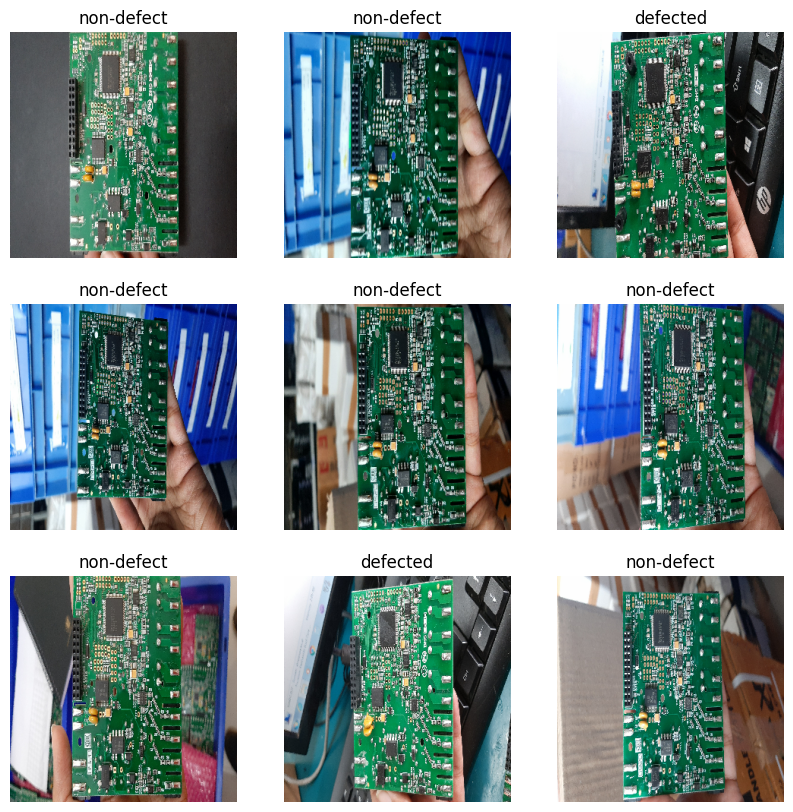

In [ ]:
# Let's see some more samples
plt.figure(figsize=(10, 10))
for images, labels in train_set.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
for images, labels in train_set:
  print(images.shape)
  print(labels.shape)
  break

(64, 299, 299, 3)
(64,)


<a id = "4"></a><br>
## Efficient Input Pipelines

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_set.cache().shuffle(1300).prefetch(buffer_size=AUTOTUNE)
val_ds = val_set.cache().prefetch(buffer_size=AUTOTUNE)

<a id = "5"></a><br>
## Data Augmentation

In [ ]:
data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal_and_vertical",input_shape=(img_height,img_width,3), seed = seed ),
    layers.RandomZoom(0.1, seed = seed ),
    layers.RandomContrast(0.3, seed = seed  )
  ]
)


<a id = "6"></a><br>
## Building a Custom Model

In [ ]:
custom_model = Sequential([

  layers.Rescaling(1./255),
  data_augmentation,

  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),


  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(1, activation = 'sigmoid')
])

In [ ]:
custom_model.compile(optimizer='adam',
                     loss='binary_crossentropy',
                     metrics=['accuracy'])

<a id = "7"></a><br>
## Callbacks

In [ ]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') == 1.0 and logs.get('val_accuracy') == 1.0 :
            print("\nReached 100% accuracy so cancelling training!")
            self.model.stop_training = True

terminate_callback =  myCallback()

In [ ]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, verbose=1,min_delta=0.01,
                              patience=5, min_lr=0.000001)



<a id = "8"></a><br>
## Custom Model Performance

In [ ]:
history1 = custom_model.fit(train_ds,
                            validation_data=val_ds,
                            epochs=20, #200
                            callbacks= [reduce_lr, terminate_callback]
)

Epoch 1/20
5/5 [==============================] - 149s 26s/step - loss: 0.5801 - accuracy: 0.7282 - val_loss: 0.5177 - val_accuracy: 0.7532 - lr: 0.0010
Epoch 2/20
5/5 [==============================] - 114s 24s/step - loss: 0.4793 - accuracy: 0.7864 - val_loss: 0.3200 - val_accuracy: 0.8961 - lr: 0.0010
Epoch 3/20
5/5 [==============================] - 115s 23s/step - loss: 0.3492 - accuracy: 0.8641 - val_loss: 0.2065 - val_accuracy: 0.9091 - lr: 0.0010
Epoch 4/20
5/5 [==============================] - 115s 23s/step - loss: 0.2614 - accuracy: 0.9094 - val_loss: 0.0678 - val_accuracy: 0.9870 - lr: 0.0010
Epoch 5/20
5/5 [==============================] - 111s 23s/step - loss: 0.1448 - accuracy: 0.9385 - val_loss: 0.1375 - val_accuracy: 0.9351 - lr: 0.0010
Epoch 6/20
5/5 [==============================] - 113s 22s/step - loss: 0.1182 - accuracy: 0.9450 - val_loss: 0.0366 - val_accuracy: 0.9740 - lr: 0.0010
Epoch 7/20
5/5 [==============================] - 122s 25s/step - loss: 0.0536 - a

In [ ]:
custom_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 299, 299, 3)       0         
                                                                 
 sequential (Sequential)     (None, 299, 299, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 299, 299, 64)      1792      
                                                                 
 max_pooling2d (MaxPooling2  (None, 149, 149, 64)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 149, 149, 64)      36928     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 74, 74, 64)        0         
 g2D)                                                 

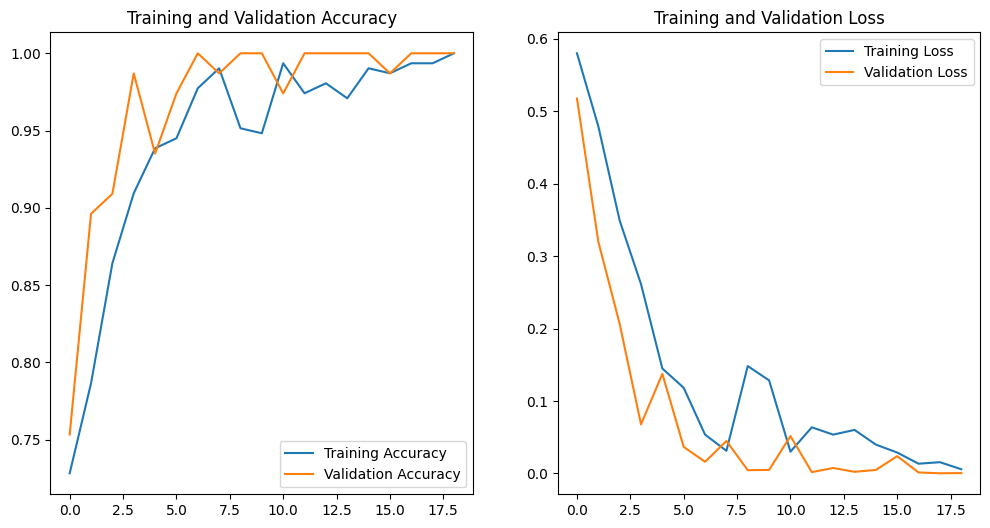

In [ ]:
acc = history1.history['accuracy']
val_acc = history1.history['val_accuracy']

loss = history1.history['loss']
val_loss = history1.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
# Importing the VGG16 model
base_model = keras.applications.VGG16(
    weights='imagenet',  # Load weights pre-trained on ImageNet.
    input_shape=(img_height, img_width, 3),
    include_top=False)

58889256/58889256 [==============================] - 0s 0us/step


In [ ]:
# Freeze the base model
base_model.trainable = False

# Create new model on top
inputs = keras.Input(shape=(img_height, img_width, 3))
x = data_augmentation(inputs)  # Apply random data augmentation
x = keras.layers.Rescaling(scale=1.0 / 255)(x)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)  # Add global average pooling layer
x = keras.layers.Dense(128, activation='relu')(x)  # Add dense layer
outputs = keras.layers.Dense(1, activation='sigmoid')(x)  # Add output layer

# Combine inputs and outputs to create model
pretrained_model = keras.Model(inputs, outputs)

In [ ]:
pretrained_model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])


In [ ]:
history2 = pretrained_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, #200
    callbacks= [reduce_lr, terminate_callback]
)

Epoch 1/30
5/5 [==============================] - 515s 113s/step - loss: 0.7395 - accuracy: 0.5113 - val_loss: 0.5507 - val_accuracy: 0.7532 - lr: 0.0010
Epoch 2/30
5/5 [==============================] - 456s 95s/step - loss: 0.6351 - accuracy: 0.7346 - val_loss: 0.6095 - val_accuracy: 0.7532 - lr: 0.0010
Epoch 3/30
5/5 [==============================] - 498s 107s/step - loss: 0.6035 - accuracy: 0.7346 - val_loss: 0.5126 - val_accuracy: 0.7532 - lr: 0.0010
Epoch 4/30
5/5 [==============================] - 501s 106s/step - loss: 0.5183 - accuracy: 0.7346 - val_loss: 0.4970 - val_accuracy: 0.7922 - lr: 0.0010
Epoch 5/30
5/5 [==============================] - 507s 107s/step - loss: 0.5071 - accuracy: 0.7929 - val_loss: 0.4820 - val_accuracy: 0.8571 - lr: 0.0010
Epoch 6/30
5/5 [==============================] - 507s 109s/step - loss: 0.4724 - accuracy: 0.7832 - val_loss: 0.4268 - val_accuracy: 0.7922 - lr: 0.0010
Epoch 7/30
5/5 [==============================] - 516s 110s/step - loss: 0.44

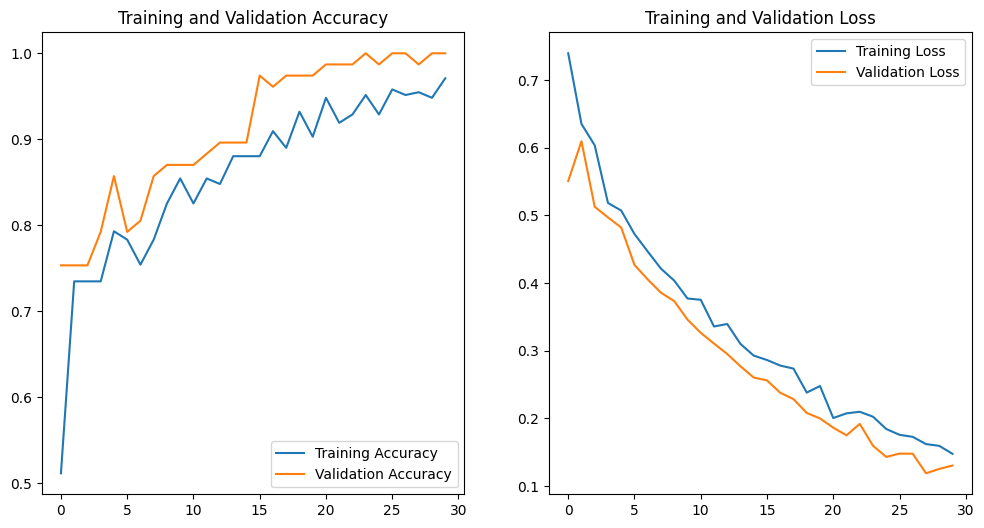

In [ ]:

acc = history2.history['accuracy']
val_acc = history2.history['val_accuracy']
loss = history2.history['loss']
val_loss = history2.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()



In [ ]:
pretrained_model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 299, 299, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 299, 299, 3)       0         
                                                                 
 rescaling_1 (Rescaling)     (None, 299, 299, 3)       0         
                                                                 
 vgg16 (Functional)          (None, 9, 9, 512)         14714688  
                                                                 
 global_average_pooling2d (  (None, 512)               0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense_2 (Dense)             (None, 128)               65664     
                                                             

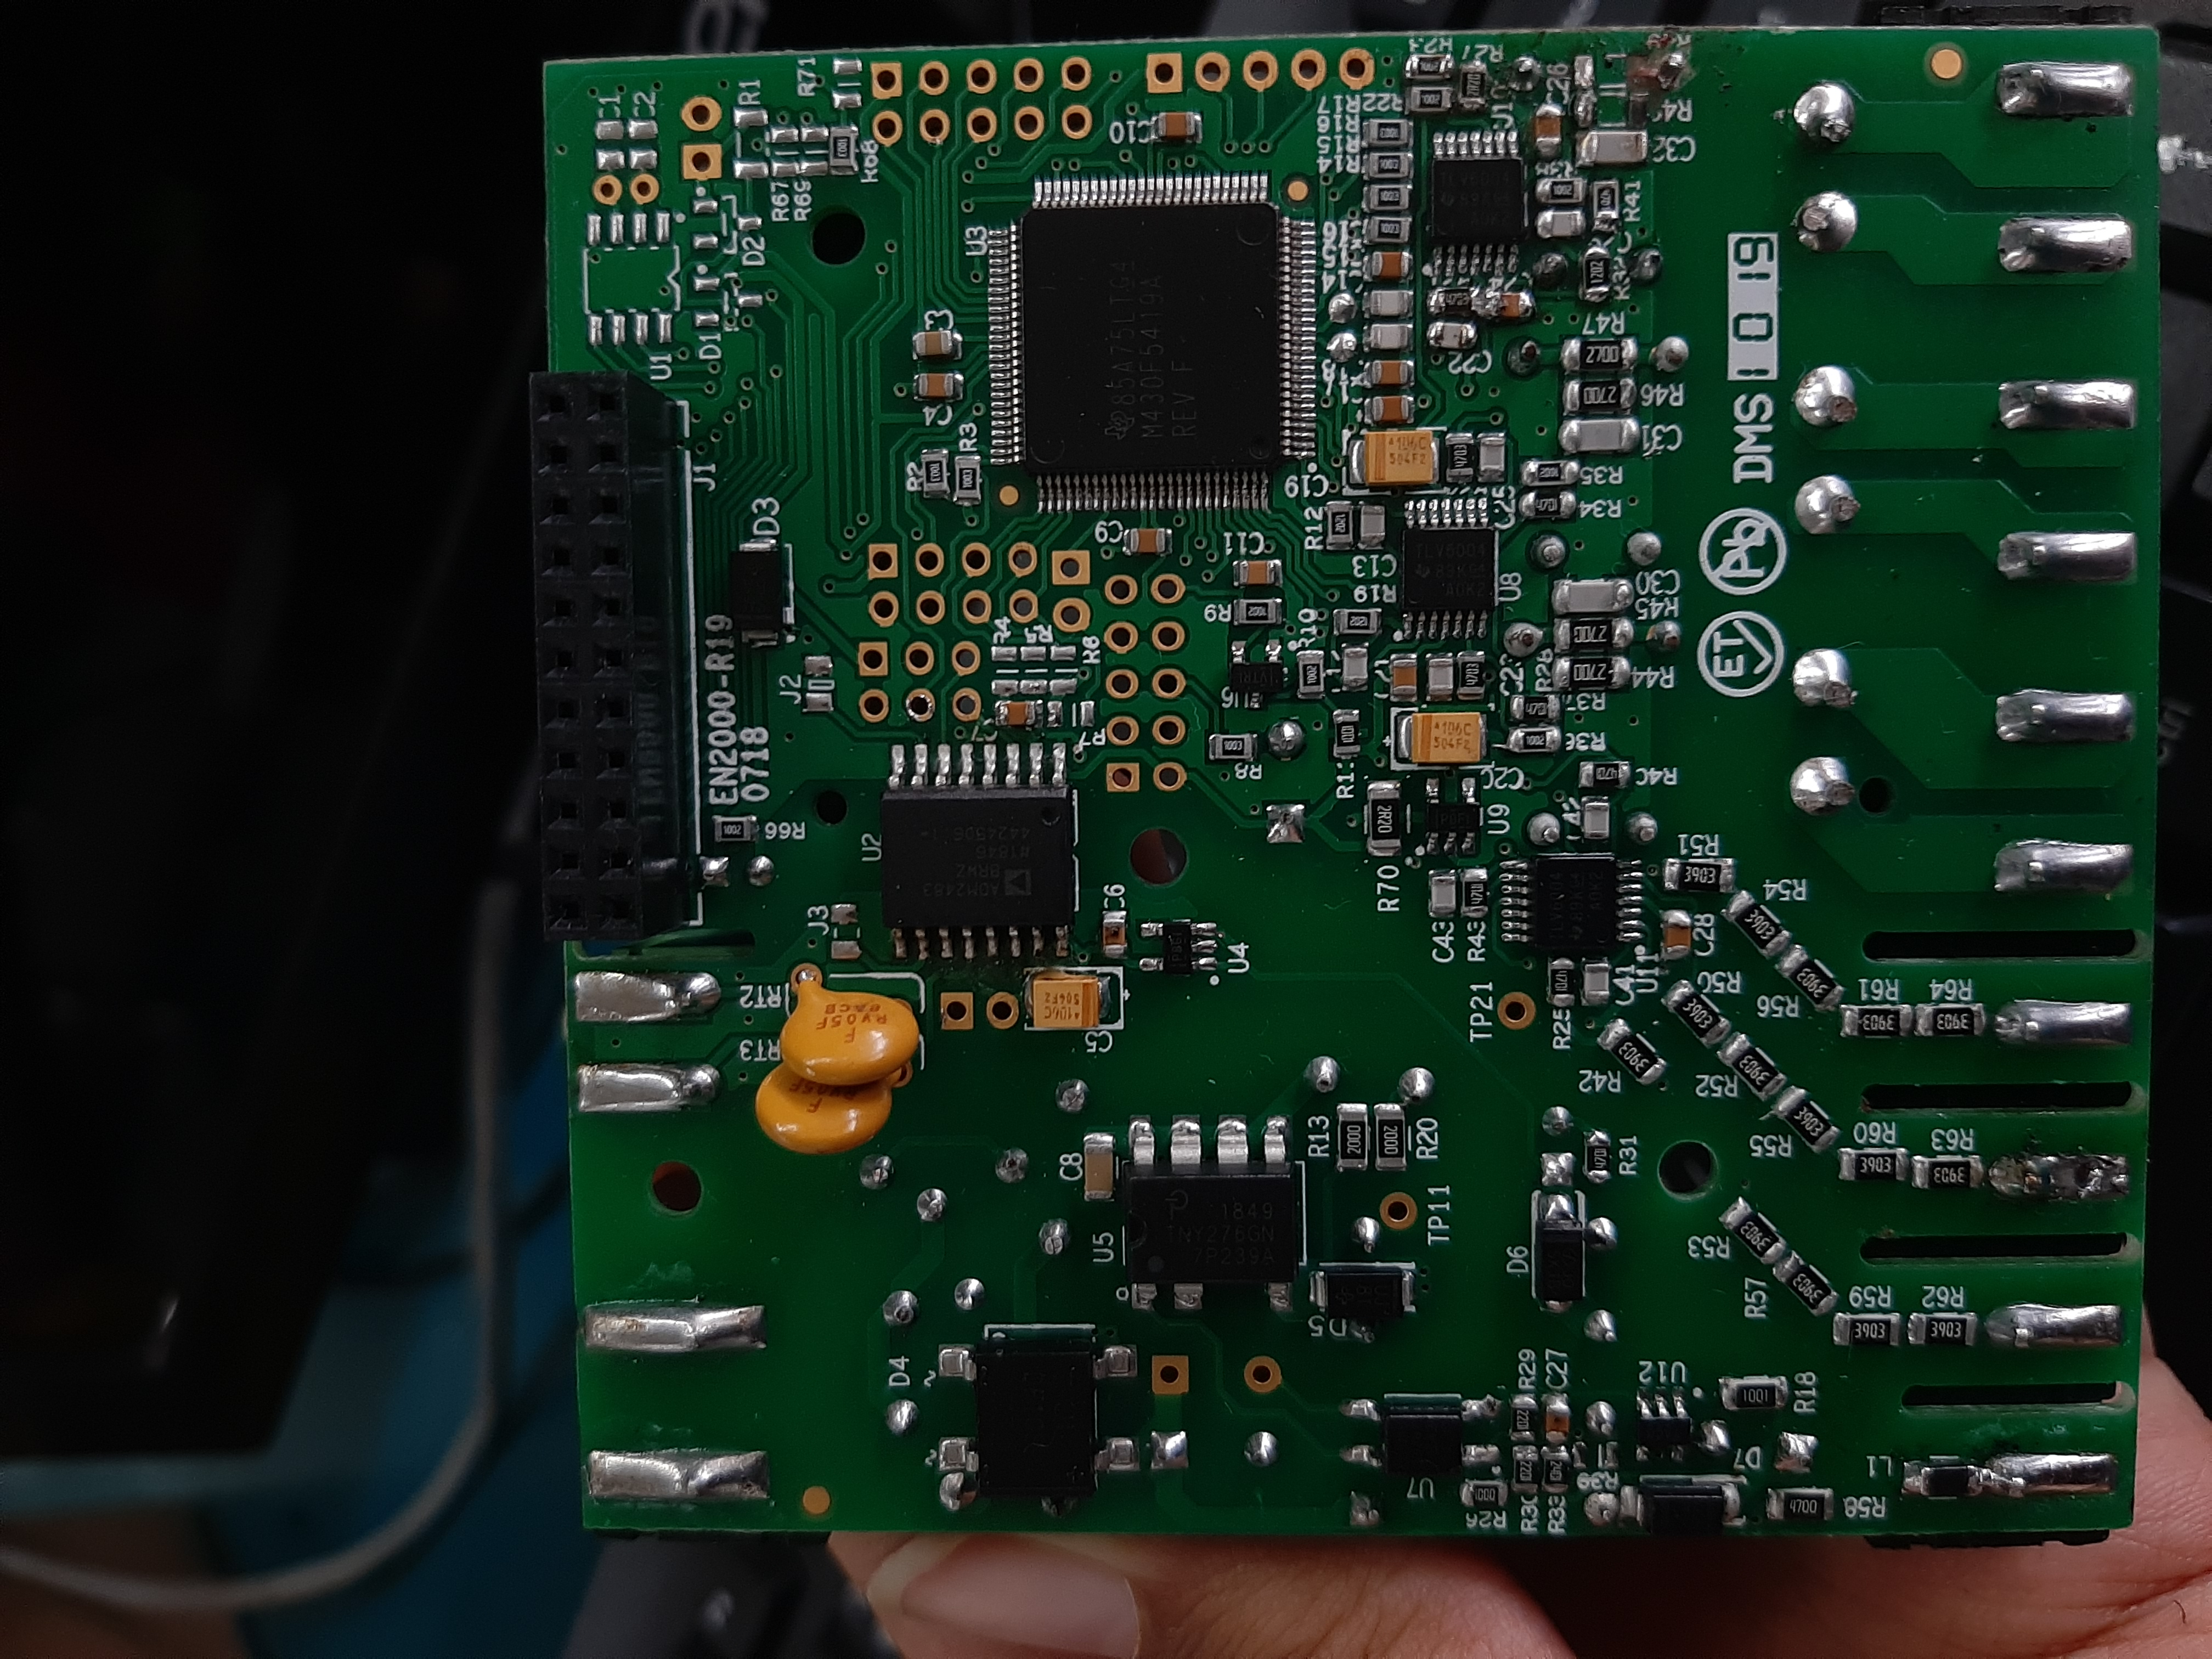

In [ ]:
# The path to our target image
img_path = '/content/drive/MyDrive/dataset/tobeaugmented/defected/20200707_160659.jpg' #'/content/drive/MyDrive/Colab Notebooks/1200px-SEG_DVD_430_-_Printed_circuit_board-4276.jpg'
display(Image(img_path))


In [ ]:
def read_and_transform_img(img_path):

    img = skimage.io.imread(img_path)
    img = skimage.transform.resize(img, (img_height,img_width))

    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)

    return img

In [ ]:
# Perform prediction
images = read_and_transform_img(img_path)
preds = pretrained_model.predict(images)
prediction = "defected" if preds <= 0.5 else "non_defected"
confidence = preds[0][0]

print("Prediction:", prediction)
print("Confidence:", confidence)

1/1 [==============================] - 2s 2s/step
Prediction: non_defected
Confidence: 0.9390374


In [ ]:
prediction = np.argmax(preds)
pct = np.max(preds)
print(pct)

0.9390374


In [ ]:
explainer = lime_image.LimeImageExplainer()


In [ ]:
explanation = explainer.explain_instance(images[0].astype('double'), custom_model.predict,
                                        top_labels=2, hide_color=0, num_samples=500)

  0%|          | 0/500 [00:00<?, ?it/s]

1/1 [==============================] - 1s 749ms/step


(-0.5, 298.5, 298.5, -0.5)

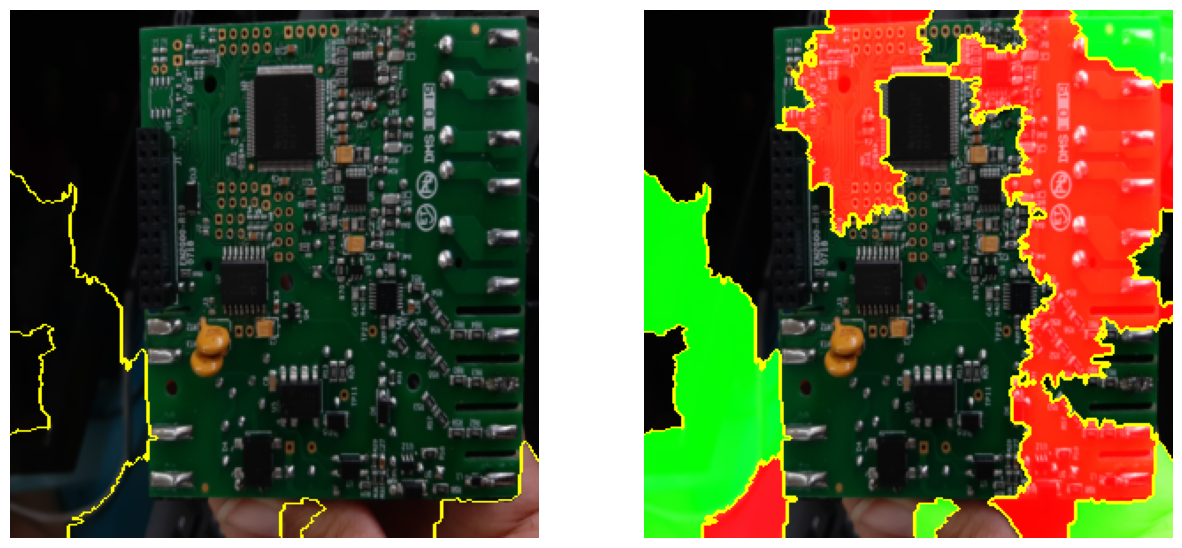

In [ ]:
from skimage.segmentation import mark_boundaries

temp_1, mask_1 = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=True, num_features=5, hide_rest=False)
temp_2, mask_2 = explanation.get_image_and_mask(explanation.top_labels[0], positive_only=False, num_features=20, hide_rest=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 15))
ax1.imshow(mark_boundaries(temp_1, mask_1))
ax2.imshow(mark_boundaries(temp_2, mask_2))
ax1.axis('off')
ax2.axis('off')